In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
PROJECT_DIR = Path(
    r"F:\AI-Driven Time-Series Forecasting and Predictive Analytics for Logistics Booking Demand"
)

DATA_PATH = PROJECT_DIR / "data" / "raw" / "BK_AUG2026.xlsx"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_DIR)
print("Input file:", DATA_PATH)
print("Output folder:", PROCESSED_DIR)

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Excel file not found: {DATA_PATH}")

Project folder: F:\AI-Driven Time-Series Forecasting and Predictive Analytics for Logistics Booking Demand
Input file: F:\AI-Driven Time-Series Forecasting and Predictive Analytics for Logistics Booking Demand\data\raw\BK_AUG2026.xlsx
Output folder: F:\AI-Driven Time-Series Forecasting and Predictive Analytics for Logistics Booking Demand\data\processed


In [3]:
excel_file = pd.ExcelFile(DATA_PATH)

print("Available sheets:", excel_file.sheet_names)

all_sheets = []

for sheet in excel_file.sheet_names:
    temp_df = pd.read_excel(DATA_PATH, sheet_name=sheet)
    temp_df["SOURCE_SHEET"] = sheet
    all_sheets.append(temp_df)

df = pd.concat(all_sheets, ignore_index=True)

print("Data loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Available sheets: ['1-15', '16-31']
Data loaded successfully!
Dataset shape: (1329629, 35)


,LRNO,NOA,BKDATE,NOA.1,AWGT,CHWGT,BKMODE,SEGMENT,DECLVALUE,CONSIGNOR,...,WITHPASS,DOORCOLL,BKGODA,TOLLCHR,REMARK,ACPARTYCODE,INVNO,EWAYBILLNO,LOADTYPE,SOURCE_SHEET
0,1014086735,1,2026-08-01 00:00:00,1.0,7.0,35.0,A,GP,13231.0,RAYMOND LIFESTYLE LTD,...,0.0,0.0,0.0,0.0,NaN,18538.0,TB10046050,262255134888,PTL,1-15
1,1014086736,1,2026-08-01 00:00:00,1.0,6.0,35.0,A,GP,16237.0,RAYMOND LIFESTYLE LTD,...,0.0,0.0,0.0,0.0,NaN,18538.0,TB10046051,232255134889,PTL,1-15
2,1014086737,1,2026-08-01 00:00:00,1.0,4.0,35.0,A,GP,6254.0,RAYMOND LIFESTYLE LTD,...,0.0,0.0,0.0,0.0,NaN,18538.0,TB10046052,292255134890,PTL,1-15
3,1014086738,1,2026-08-01 00:00:00,1.0,6.0,35.0,A,GP,9197.0,RAYMOND LIFESTYLE LTD,...,0.0,0.0,0.0,0.0,NaN,18538.0,TB10046053,262255134891,PTL,1-15
4,1014086739,1,2026-08-01 00:00:00,1.0,7.0,35.0,A,GP,7981.0,RAYMOND LIFESTYLE LTD,...,0.0,0.0,0.0,0.0,NaN,18538.0,TB10046054,232255134892,PTL,1-15


In [4]:
df.columns = (
    df.columns
    .str.strip()
    .str.upper()
    .str.replace(" ", "_")
)

print("Updated column names:")
print(df.columns.tolist())

Updated column names:
['LRNO', 'NOA', 'BKDATE', 'NOA.1', 'AWGT', 'CHWGT', 'BKMODE', 'SEGMENT', 'DECLVALUE', 'CONSIGNOR', 'CONSIGNEE', 'SENDTIN', 'RECTIN', 'COMODITY', 'DESCRIPTION', 'PACKING', 'GCTOTAL', 'FRGT', 'ST', 'HAMALI', 'VSC', 'CRC', 'DDL', 'OTHERS', 'CART', 'WITHPASS', 'DOORCOLL', 'BKGODA', 'TOLLCHR', 'REMARK', 'ACPARTYCODE', 'INVNO', 'EWAYBILLNO', 'LOADTYPE', 'SOURCE_SHEET']


In [5]:
print("Number of rows:", len(df))
print("Number of columns:", len(df.columns))

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

Number of rows: 1329629
Number of columns: 35

Data types:
LRNO             object
NOA              object
BKDATE           object
NOA.1           float64
AWGT            float64
CHWGT           float64
BKMODE           object
SEGMENT          object
DECLVALUE       float64
CONSIGNOR        object
CONSIGNEE        object
SENDTIN          object
RECTIN           object
COMODITY         object
DESCRIPTION      object
PACKING          object
GCTOTAL          object
FRGT             object
ST               object
HAMALI           object
VSC              object
CRC             float64
DDL             float64
OTHERS          float64
CART            float64
WITHPASS        float64
DOORCOLL        float64
BKGODA          float64
TOLLCHR         float64
REMARK           object
ACPARTYCODE     float64
INVNO            object
EWAYBILLNO       object
LOADTYPE         object
SOURCE_SHEET     object
dtype: object

Missing values:
LRNO                 0
NOA                  1
BKDATE               1
N

In [ ]:
print("Before removing empty rows and columns:", df.shape)

df = df.dropna(how="all")
df = df.dropna(axis=1, how="all")

print("After removing empty rows and columns:", df.shape)

Before removing empty rows and columns: (1329629, 35)


In [11]:
DATA_PATH = r"F:\AI-Driven Time-Series Forecasting and Predictive Analytics for Logistics Booking Demand\data\processed\cleaned_logistics_data.csv"

DAILY_PATH = r"F:\AI-Driven Time-Series Forecasting and Predictive Analytics for Logistics Booking Demand\data\processed\daily_booking_demand.csv"

df = pd.read_csv(DATA_PATH)
daily_bookings = pd.read_csv(DAILY_PATH)

print("Datasets loaded successfully!")
print("Dataset shape:", df.shape)
print("Daily bookings shape:", daily_bookings.shape)

Datasets loaded successfully!
Dataset shape: (158274, 35)
Daily bookings shape: (16, 2)


In [12]:
if "BKDATE" in df.columns:
    df["BKDATE"] = pd.to_datetime(
        df["BKDATE"],
        errors="coerce",
        dayfirst=True
    )

    print("Booking date converted to datetime.")
    print("Invalid dates:", df["BKDATE"].isna().sum())
else:
    print("BKDATE column not found.")

Booking date converted to datetime.
Invalid dates: 28471


In [13]:
numeric_columns = [
    "AWGT",
    "CHWGT",
    "FRGT"
]

for column in numeric_columns:
    if column in df.columns:
        df[column] = pd.to_numeric(
            df[column],
            errors="coerce"
        )

print("Numeric conversion completed.")
print(df.dtypes)

Numeric conversion completed.
LRNO                     int64
NOA                      int64
BKDATE          datetime64[ns]
NOA.1                  float64
AWGT                   float64
CHWGT                  float64
BKMODE                  object
SEGMENT                 object
DECLVALUE              float64
CONSIGNOR               object
CONSIGNEE               object
SENDTIN                 object
RECTIN                  object
COMODITY                object
DESCRIPTION             object
PACKING                 object
GCTOTAL                float64
FRGT                   float64
ST                     float64
HAMALI                 float64
VSC                    float64
CRC                    float64
DDL                    float64
OTHERS                 float64
CART                   float64
WITHPASS               float64
DOORCOLL               float64
BKGODA                 float64
TOLLCHR                float64
REMARK                  object
ACPARTYCODE            float64
INVNO    

In [14]:
missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

missing_summary = missing_summary.sort_values(
    by="Missing_Percentage",
    ascending=False
)

missing_summary

,Missing_Count,Missing_Percentage
EWAYBILLNO,85047,53.73
BKDATE,28471,17.99
REMARK,24052,15.20
INVNO,9795,6.19
LRNO,0,0.00
WITHPASS,0,0.00
VSC,0,0.00
CRC,0,0.00
DDL,0,0.00
OTHERS,0,0.00


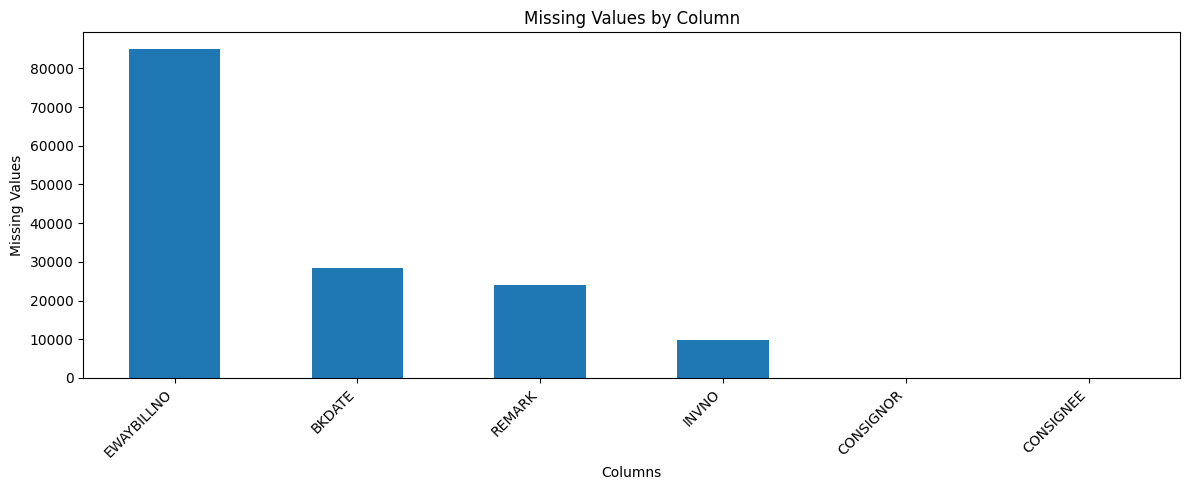

In [16]:
import matplotlib.pyplot as plt

missing_data = df.isnull().sum()
missing_data = missing_data[missing_data > 0]

if not missing_data.empty:
    plt.figure(figsize=(12, 5))

    missing_data.sort_values(ascending=False).plot(
        kind="bar"
    )

    plt.title("Missing Values by Column")
    plt.xlabel("Columns")
    plt.ylabel("Missing Values")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found.")

In [18]:
from pathlib import Path

PROJECT_DIR = Path(
    r"F:\AI-Driven Time-Series Forecasting and Predictive Analytics for Logistics Booking Demand"
)

PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

print("Processed folder:", PROCESSED_DIR)

Processed folder: F:\AI-Driven Time-Series Forecasting and Predictive Analytics for Logistics Booking Demand\data\processed


In [19]:
if "BKDATE" in df.columns:
    invalid_date_rows = df[df["BKDATE"].isna()].copy()

    invalid_date_rows.to_csv(
        PROCESSED_DIR / "invalid_booking_dates.csv",
        index=False
    )

    df = df.dropna(subset=["BKDATE"]).copy()

    print("Rows with invalid dates:", len(invalid_date_rows))
    print("Rows remaining:", len(df))
    print("Invalid dates saved successfully!")

else:
    raise ValueError(
        "BKDATE column is required for time-series forecasting."
    )

Rows with invalid dates: 28471
Rows remaining: 129803
Invalid dates saved successfully!


In [20]:
duplicate_count = df.duplicated().sum()

print("Exact duplicate rows:", duplicate_count)

Exact duplicate rows: 0


In [21]:
before = len(df)

df = df.drop_duplicates().copy()

after = len(df)

print("Rows before:", before)
print("Rows after:", after)
print("Exact duplicates removed:", before - after)

Rows before: 129803
Rows after: 129803
Exact duplicates removed: 0


In [22]:
check_columns = ["AWGT", "CHWGT", "FRGT"]

for column in check_columns:
    if column in df.columns:
        invalid = df[df[column] < 0]

        print(f"\n{column}: {len(invalid)} negative values")
        display(invalid.head(10))


AWGT: 0 negative values


,LRNO,NOA,BKDATE,NOA.1,AWGT,CHWGT,BKMODE,SEGMENT,DECLVALUE,CONSIGNOR,...,WITHPASS,DOORCOLL,BKGODA,TOLLCHR,REMARK,ACPARTYCODE,INVNO,EWAYBILLNO,LOADTYPE,SOURCE_SHEET



CHWGT: 0 negative values


,LRNO,NOA,BKDATE,NOA.1,AWGT,CHWGT,BKMODE,SEGMENT,DECLVALUE,CONSIGNOR,...,WITHPASS,DOORCOLL,BKGODA,TOLLCHR,REMARK,ACPARTYCODE,INVNO,EWAYBILLNO,LOADTYPE,SOURCE_SHEET



FRGT: 0 negative values


,LRNO,NOA,BKDATE,NOA.1,AWGT,CHWGT,BKMODE,SEGMENT,DECLVALUE,CONSIGNOR,...,WITHPASS,DOORCOLL,BKGODA,TOLLCHR,REMARK,ACPARTYCODE,INVNO,EWAYBILLNO,LOADTYPE,SOURCE_SHEET


In [24]:
import numpy as np

for column in ["AWGT", "CHWGT", "FRGT"]:
    if column in df.columns:
        negative_count = (df[column] < 0).sum()

        df.loc[df[column] < 0, column] = np.nan

        print(
            f"{column}: {negative_count} negative values "
            "changed to missing"
        )

AWGT: 0 negative values changed to missing
CHWGT: 0 negative values changed to missing
FRGT: 0 negative values changed to missing


In [25]:
for column in ["AWGT", "CHWGT", "FRGT"]:
    if column in df.columns:
        print(f"\n{column}")
        print("Missing:", df[column].isna().sum())
        print("Median:", df[column].median())


AWGT
Missing: 0
Median: 62.0

CHWGT
Missing: 0
Median: 75.0

FRGT
Missing: 0
Median: 655.0


In [26]:
categorical_columns = [
    "BKMODE",
    "SEGMENT",
    "COMODITY",
    "LOADTYPE"
]

for column in categorical_columns:
    if column in df.columns:
        print(f"\n{column}")
        print(df[column].value_counts(dropna=False).head(20))


BKMODE
BKMODE
T    111568
P     15606
A      2629
Name: count, dtype: int64

SEGMENT
SEGMENT
GP    129803
Name: count, dtype: int64

COMODITY
COMODITY
CLOTH                 33830
MACHINERY ITEMS       10548
HARDWARE               6582
GENERAL ITEMS          5840
MEDICINE               5300
AUTO PARTS             5144
INDUSTRIAL GOODS       5112
ELECTRICAL GOODS       4103
FOOD ITEMS             3403
AGRO CHEMICALS         2902
MOTOR PARTS            2847
STATIONERY GOODS       2629
PLASTIC ITEMS          2379
BOOKS                  2322
AGRICULTURAL GOODS     2029
MEDICAL EQUIPMENTS     1587
PUMPS AND MOTORS       1391
PACKING MATERIAL       1368
RUBBER GOODS           1147
FOOD GRAINS            1139
Name: count, dtype: int64

LOADTYPE
LOADTYPE
PTL     129796
CFTL         4
FTL          3
Name: count, dtype: int64


In [27]:
for column in categorical_columns:
    if column in df.columns:
        df[column] = (
            df[column]
            .astype("string")
            .str.strip()
            .str.upper()
        )

print("Categorical values standardized.")

Categorical values standardized.


In [28]:
print("Earliest booking date:", df["BKDATE"].min())
print("Latest booking date:", df["BKDATE"].max())
print("Missing booking dates:", df["BKDATE"].isna().sum())

Earliest booking date: 2026-01-08 00:00:00
Latest booking date: 2026-12-08 00:00:00
Missing booking dates: 0


In [29]:
daily_bookings = (
    df.groupby(df["BKDATE"].dt.normalize())
      .size()
      .reset_index(name="BOOKING_COUNT")
)

daily_bookings = daily_bookings.rename(
    columns={"BKDATE": "DATE"}
)

daily_bookings = daily_bookings.sort_values("DATE")

daily_bookings.head(10)

,DATE,BOOKING_COUNT
0,2026-01-08,13691
1,2026-02-08,1913
2,2026-03-08,11381
3,2026-04-08,12809
4,2026-05-08,12559
5,2026-06-08,13412
6,2026-07-08,12454
7,2026-08-08,13093
8,2026-09-08,1020
9,2026-10-08,11667


In [30]:
print("Number of dates:", len(daily_bookings))
print("First date:", daily_bookings["DATE"].min())
print("Last date:", daily_bookings["DATE"].max())

print("\nDaily booking statistics:")
print(daily_bookings["BOOKING_COUNT"].describe())

Number of dates: 12
First date: 2026-01-08 00:00:00
Last date: 2026-12-08 00:00:00

Daily booking statistics:
count       12.000000
mean     10816.916667
std       4419.535094
min       1020.000000
25%      11595.500000
50%      12684.000000
75%      12968.500000
max      13691.000000
Name: BOOKING_COUNT, dtype: float64


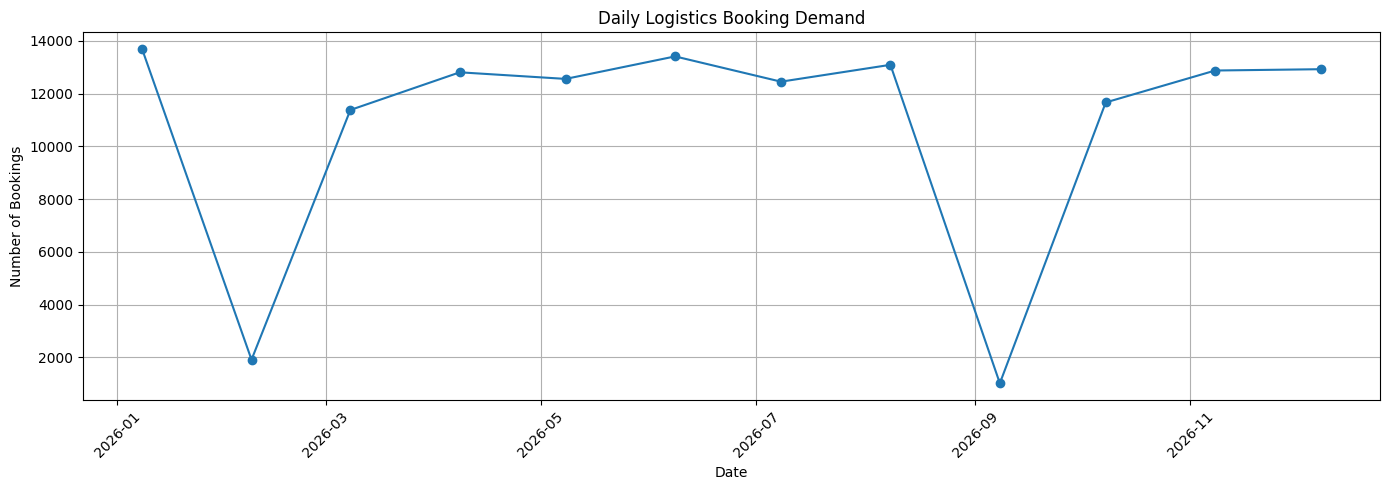

In [31]:
plt.figure(figsize=(14, 5))

plt.plot(
    daily_bookings["DATE"],
    daily_bookings["BOOKING_COUNT"],
    marker="o"
)

plt.title("Daily Logistics Booking Demand")
plt.xlabel("Date")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [32]:
all_dates = pd.date_range(
    start=daily_bookings["DATE"].min(),
    end=daily_bookings["DATE"].max(),
    freq="D"
)

existing_dates = pd.DatetimeIndex(daily_bookings["DATE"])

missing_dates = all_dates.difference(existing_dates)

print("Missing calendar dates:", len(missing_dates))
print(missing_dates.tolist())

Missing calendar dates: 323
[Timestamp('2026-01-09 00:00:00'), Timestamp('2026-01-10 00:00:00'), Timestamp('2026-01-11 00:00:00'), Timestamp('2026-01-12 00:00:00'), Timestamp('2026-01-13 00:00:00'), Timestamp('2026-01-14 00:00:00'), Timestamp('2026-01-15 00:00:00'), Timestamp('2026-01-16 00:00:00'), Timestamp('2026-01-17 00:00:00'), Timestamp('2026-01-18 00:00:00'), Timestamp('2026-01-19 00:00:00'), Timestamp('2026-01-20 00:00:00'), Timestamp('2026-01-21 00:00:00'), Timestamp('2026-01-22 00:00:00'), Timestamp('2026-01-23 00:00:00'), Timestamp('2026-01-24 00:00:00'), Timestamp('2026-01-25 00:00:00'), Timestamp('2026-01-26 00:00:00'), Timestamp('2026-01-27 00:00:00'), Timestamp('2026-01-28 00:00:00'), Timestamp('2026-01-29 00:00:00'), Timestamp('2026-01-30 00:00:00'), Timestamp('2026-01-31 00:00:00'), Timestamp('2026-02-01 00:00:00'), Timestamp('2026-02-02 00:00:00'), Timestamp('2026-02-03 00:00:00'), Timestamp('2026-02-04 00:00:00'), Timestamp('2026-02-05 00:00:00'), Timestamp('2026-02-

In [33]:
# Set this to True only after confirming that missing dates
# mean zero bookings, not missing source data.
MISSING_DATE_MEANS_ZERO = False

daily_bookings = (
    daily_bookings
    .set_index("DATE")
    .reindex(all_dates)
)

daily_bookings.index.name = "DATE"

if MISSING_DATE_MEANS_ZERO:
    daily_bookings["BOOKING_COUNT"] = (
        daily_bookings["BOOKING_COUNT"].fillna(0)
    )

daily_bookings = daily_bookings.reset_index()

daily_bookings.head(10)

,DATE,BOOKING_COUNT
0,2026-01-08,13691.0
1,2026-01-09,NaN
2,2026-01-10,NaN
3,2026-01-11,NaN
4,2026-01-12,NaN
5,2026-01-13,NaN
6,2026-01-14,NaN
7,2026-01-15,NaN
8,2026-01-16,NaN
9,2026-01-17,NaN


In [34]:
cleaned_file = PROCESSED_DIR / "cleaned_logistics_data.csv"

df.to_csv(cleaned_file, index=False)

print("Cleaned transaction data saved to:")
print(cleaned_file)



Cleaned transaction data saved to:
F:\AI-Driven Time-Series Forecasting and Predictive Analytics for Logistics Booking Demand\data\processed\cleaned_logistics_data.csv


In [35]:
daily_file = PROCESSED_DIR / "daily_booking_demand.csv"

daily_bookings.to_csv(daily_file, index=False)

print("Daily booking data saved to:")
print(daily_file)

Daily booking data saved to:
F:\AI-Driven Time-Series Forecasting and Predictive Analytics for Logistics Booking Demand\data\processed\daily_booking_demand.csv


In [36]:
print("=" * 50)
print("FINAL DATA CLEANING REPORT")
print("=" * 50)

print("\nDataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nBooking date range:")
print(df["BKDATE"].min(), "to", df["BKDATE"].max())

print("\nDaily booking records:", len(daily_bookings))

print("\nSaved files:")
print(cleaned_file)
print(daily_file)

print("\nDATA CLEANING COMPLETED")

FINAL DATA CLEANING REPORT

Dataset shape: (129803, 35)

Missing values:
LRNO                0
NOA                 0
BKDATE              0
NOA.1               0
AWGT                0
CHWGT               0
BKMODE              0
SEGMENT             0
DECLVALUE           0
CONSIGNOR           1
CONSIGNEE           1
SENDTIN             0
RECTIN              0
COMODITY            0
DESCRIPTION         0
PACKING             0
GCTOTAL             0
FRGT                0
ST                  0
HAMALI              0
VSC                 0
CRC                 0
DDL                 0
OTHERS              0
CART                0
WITHPASS            0
DOORCOLL            0
BKGODA              0
TOLLCHR             0
REMARK          19714
ACPARTYCODE         0
INVNO            8005
EWAYBILLNO      69823
LOADTYPE            0
SOURCE_SHEET        0
dtype: int64

Duplicate rows: 0

Booking date range:
2026-01-08 00:00:00 to 2026-12-08 00:00:00

Daily booking records: 335

Saved files:
F:\AI-Driven Time-S